# 02 — Post-traitement du PINN
Affichage des historiques de pertes et des champs prédits par le réseau.
Cette notebook charge les 16 modèles entraînés via `script/benchmark_combinations.py`,
trace les courbes de perte par époque, puis génère les tracés de fields et l'animation
pour le meilleur modèle (selon RMSE alpha moyen).

In [1]:
from pathlib import Path
import sys
import json

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
print('Répertoire du projet :', ROOT)

from visualization import plot_fields, animate_comparison, load_model, plot_history, plot_histories

Répertoire du projet : /home/ludodo/SINN


In [2]:
# Charger les résultats du benchmark
summary = json.load(open(ROOT / 'reports' / 'summary.json'))
model_table = json.load(open(ROOT / 'reports' / 'model_table.json'))


In [3]:
pd.DataFrame(summary)

,model_name,combination,use_fourier_features,use_adaptive_sampling,use_temporal_segmentation,use_adaptive_loss_weights,train_time_s,mean_rmse_u,mean_rmse_v,mean_rmse_p,mean_rmse_alpha
0,model_ff0_as0_ts0_alw0,ffFalse_asampFalse_tsFalse_alwFalse,False,False,False,False,477.298609,0.769003,0.187131,4327.725943,0.246923
1,model_ff0_as0_ts0_alw1,ffFalse_asampFalse_tsFalse_alwTrue,False,False,False,True,741.071565,0.770382,0.186532,4325.414730,0.396807
2,model_ff0_as0_ts1_alw0,ffFalse_asampFalse_tsTrue_alwFalse,False,False,True,False,493.987273,0.769158,0.187173,4202.848269,0.492475
3,model_ff0_as0_ts1_alw1,ffFalse_asampFalse_tsTrue_alwTrue,False,False,True,True,685.508640,0.768226,0.186829,4217.666459,0.490539
4,model_ff0_as1_ts0_alw0,ffFalse_asampTrue_tsFalse_alwFalse,False,True,False,False,394.138076,0.770190,0.187234,4280.500975,0.330303
5,model_ff0_as1_ts0_alw1,ffFalse_asampTrue_tsFalse_alwTrue,False,True,False,True,603.106115,0.769198,0.190057,4295.177875,0.433446
6,model_ff0_as1_ts1_alw0,ffFalse_asampTrue_tsTrue_alwFalse,False,True,True,False,429.781743,0.769278,0.186701,4254.540740,0.493509
7,model_ff0_as1_ts1_alw1,ffFalse_asampTrue_tsTrue_alwTrue,False,True,True,True,701.272501,0.769549,0.186839,4217.747711,0.492464
8,model_ff1_as0_ts0_alw0,ffTrue_asampFalse_tsFalse_alwFalse,True,False,False,False,510.045792,0.769205,0.187040,4252.375063,0.460471
9,model_ff1_as0_ts0_alw1,ffTrue_asampFalse_tsFalse_alwTrue,True,False,False,True,901.526948,0.769813,0.186897,4215.662773,0.486048


model_ff0_as0_ts1_alw1
model_ff0_as1_ts1_alw1
model_ff1_as0_ts1_alw0
model_ff1_as1_ts1_alw1
model_ff0_as1_ts0_alw1
model_ff1_as0_ts0_alw1
model_ff1_as1_ts0_alw0
model_ff1_as1_ts1_alw0
model_ff0_as0_ts1_alw0
model_ff0_as1_ts0_alw0
model_ff0_as1_ts1_alw0
model_ff0_as0_ts0_alw0
model_ff1_as0_ts1_alw1
model_ff1_as0_ts0_alw0
model_ff0_as0_ts0_alw1
model_ff1_as1_ts0_alw1


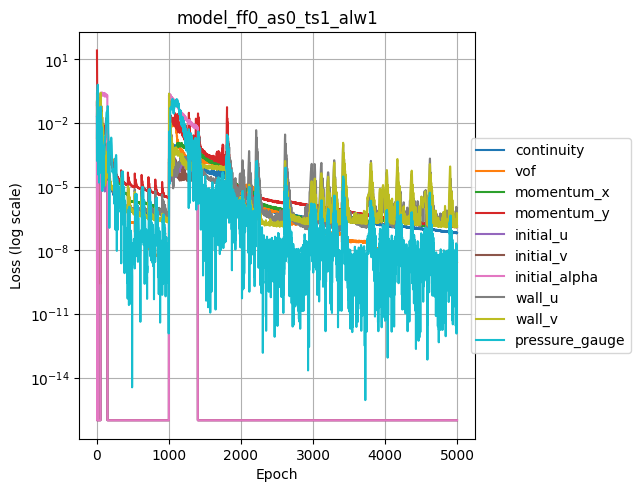

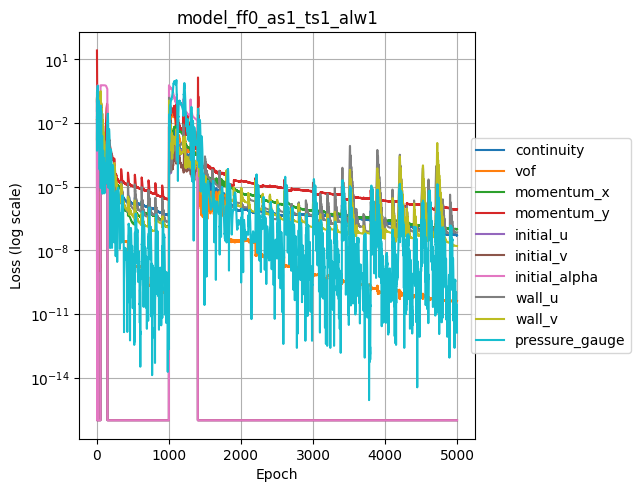

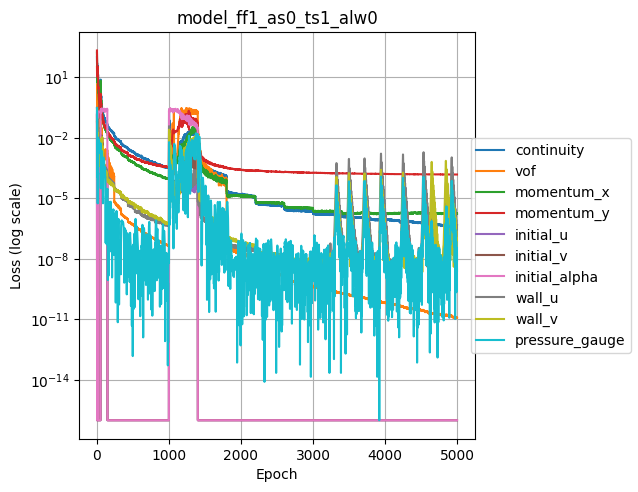

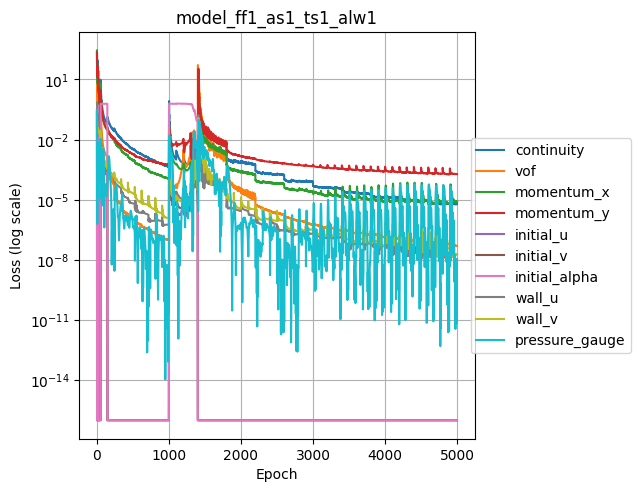

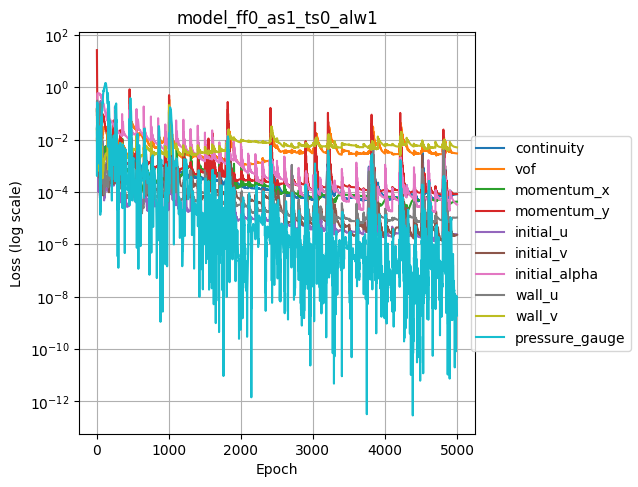

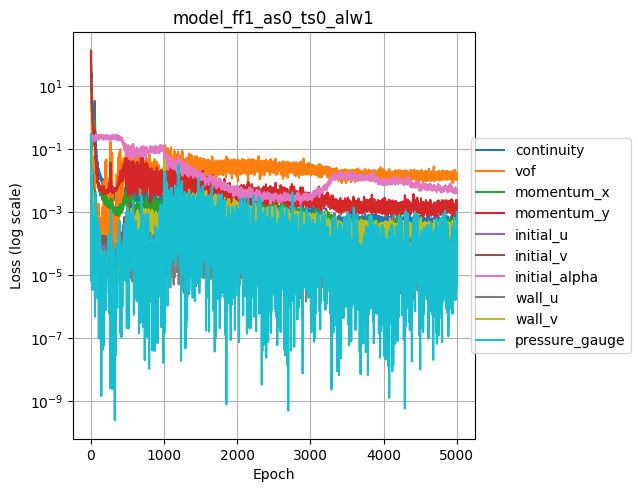

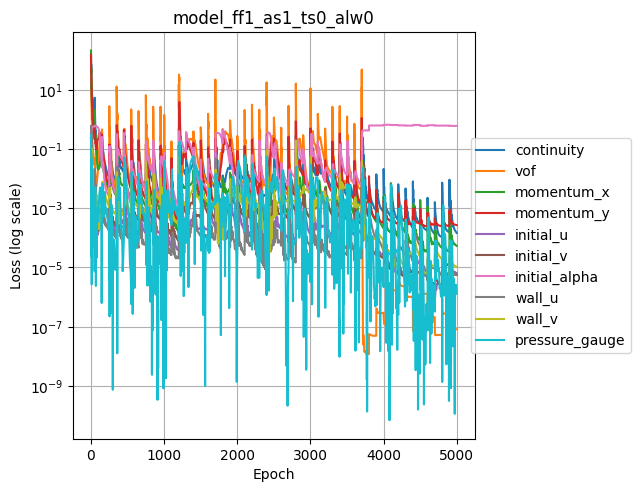

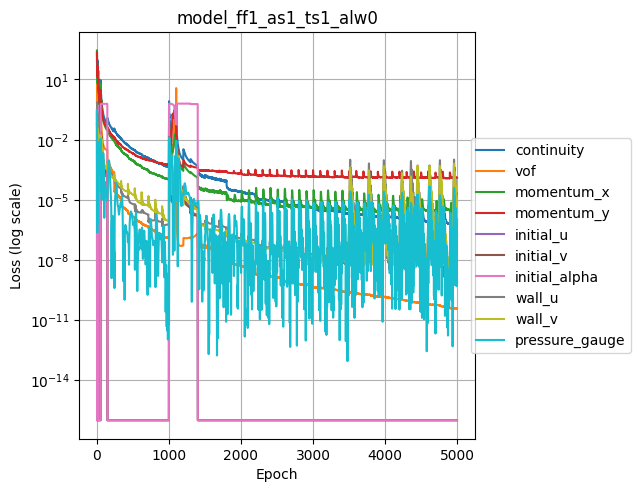

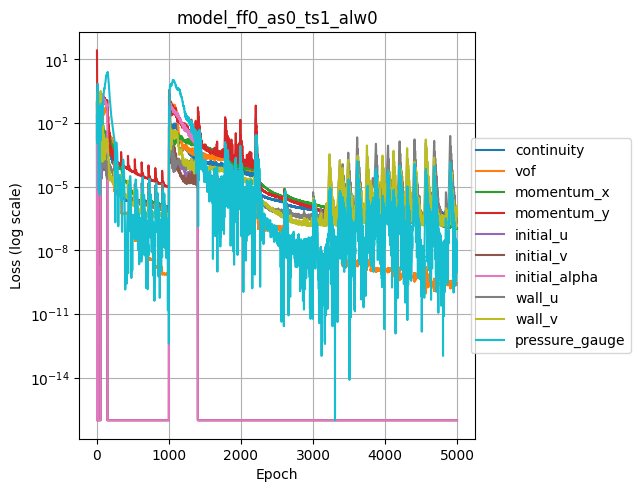

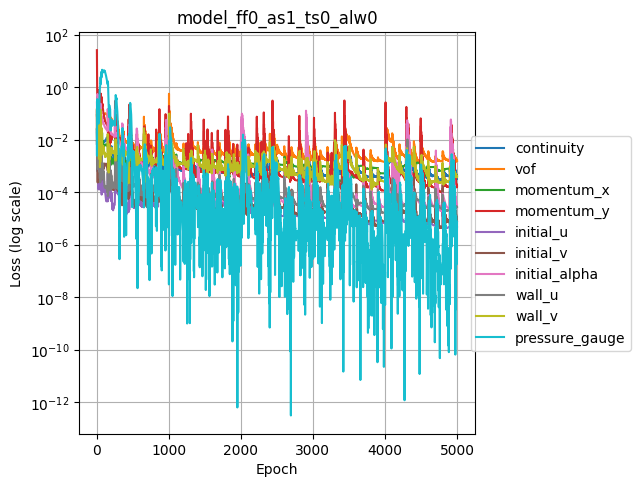

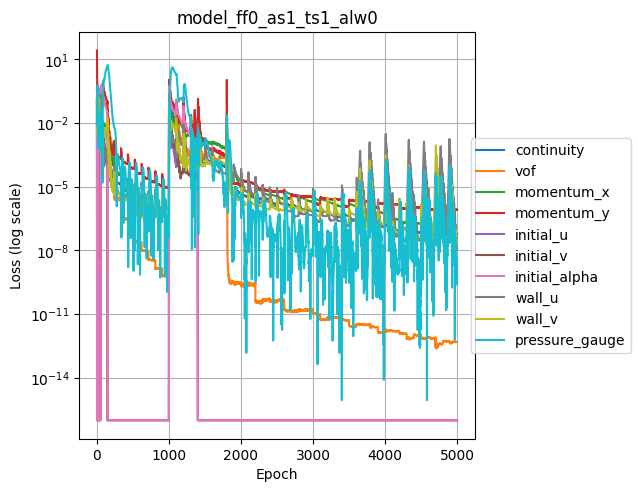

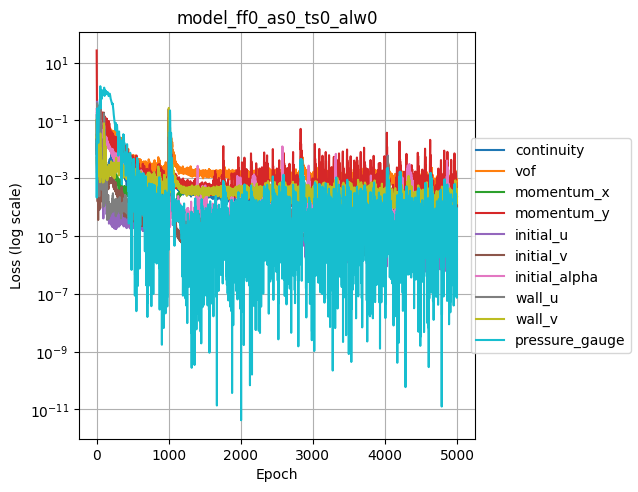

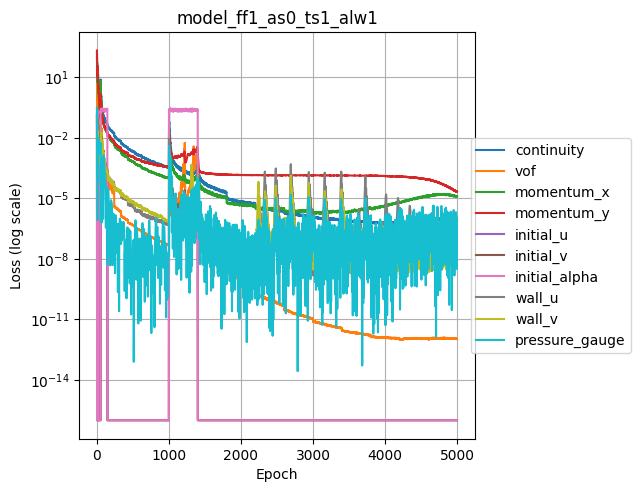

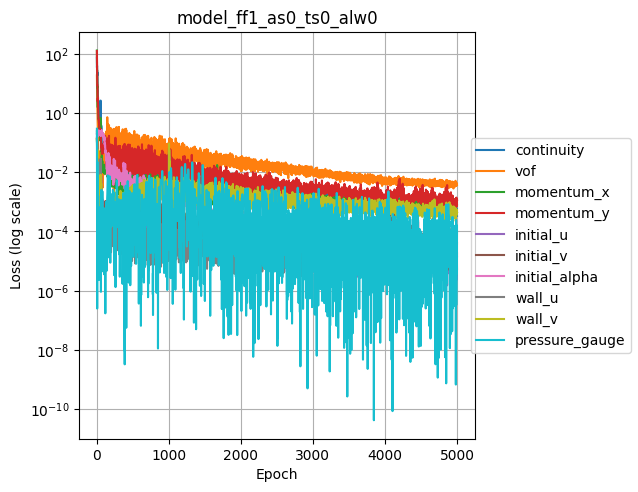

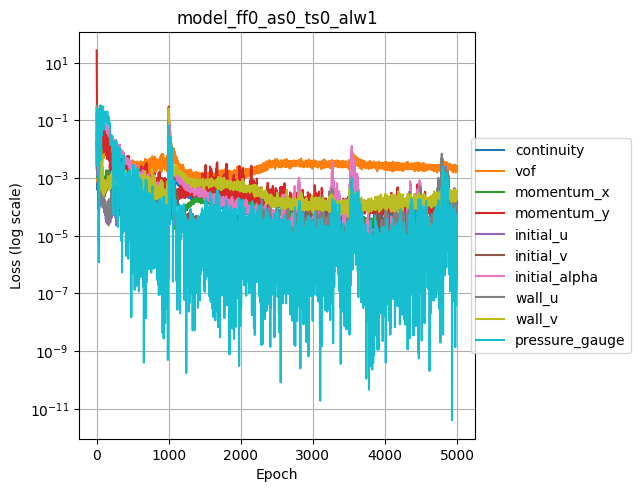

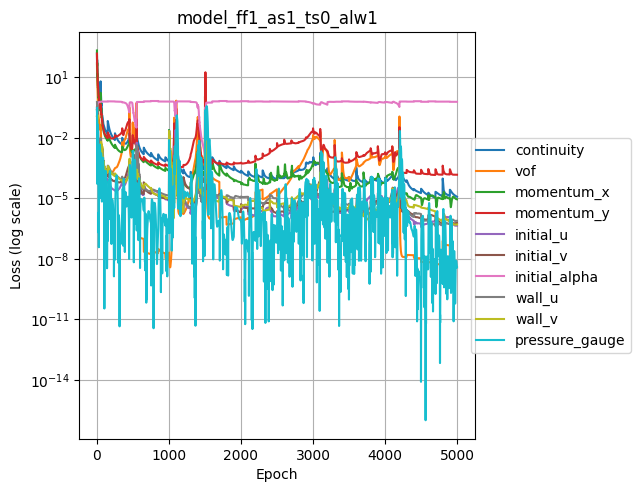

In [4]:
models_path = ROOT / "models"
for m in models_path.iterdir():
    print(m.name)
    plot_history(
        models_path / m.name / "history.json",
        use_same_figure=True,
        title=m.name)


[PosixPath('/home/ludodo/SINN/models/model_ff0_as0_ts1_alw1/history.json'), PosixPath('/home/ludodo/SINN/models/model_ff0_as1_ts1_alw1/history.json'), PosixPath('/home/ludodo/SINN/models/model_ff1_as0_ts1_alw0/history.json'), PosixPath('/home/ludodo/SINN/models/model_ff1_as1_ts1_alw1/history.json'), PosixPath('/home/ludodo/SINN/models/model_ff0_as1_ts0_alw1/history.json'), PosixPath('/home/ludodo/SINN/models/model_ff1_as0_ts0_alw1/history.json'), PosixPath('/home/ludodo/SINN/models/model_ff1_as1_ts0_alw0/history.json'), PosixPath('/home/ludodo/SINN/models/model_ff1_as1_ts1_alw0/history.json'), PosixPath('/home/ludodo/SINN/models/model_ff0_as0_ts1_alw0/history.json'), PosixPath('/home/ludodo/SINN/models/model_ff0_as1_ts0_alw0/history.json'), PosixPath('/home/ludodo/SINN/models/model_ff0_as1_ts1_alw0/history.json'), PosixPath('/home/ludodo/SINN/models/model_ff0_as0_ts0_alw0/history.json'), PosixPath('/home/ludodo/SINN/models/model_ff1_as0_ts1_alw1/history.json'), PosixPath('/home/ludodo/

(<Figure size 1200x600 with 1 Axes>,
 <Axes: title={'center': 'Loss comparison'}, xlabel='Epoch', ylabel='Loss (log scale)'>)

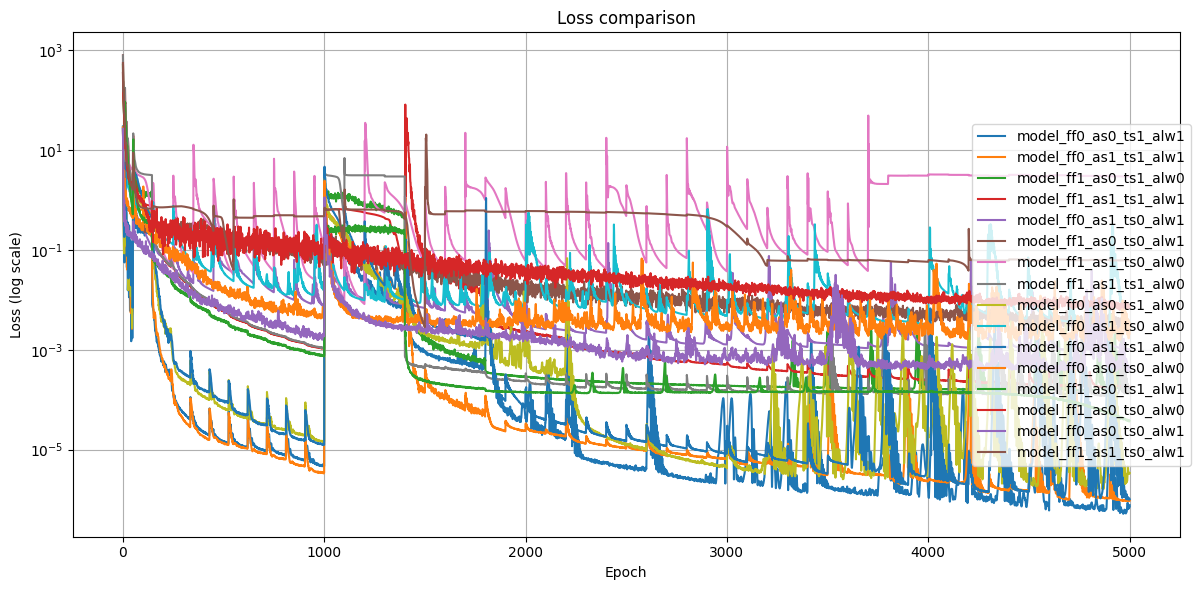

In [5]:
from visualization import plot_histories
paths = []
names = []
for m in models_path.iterdir():
    paths.append(models_path / m.name / "history.json")
    names.append(m.name)
print(paths)
plot_histories(paths, names)
